# Qo'lyozma harflarni aniqlash — EMNIST Letters (CNN)

**Mavzu:** Konvolyutsion neyron tarmoqlari (CNN) asosida tasvirlarni tasniflash modelini ishlab chiqish.

**Ma'lumotlar to'plami:** EMNIST Letters (Kaggle: `crawford/emnist`) — 26 ta sinf (lotin alifbosidagi A–Z harflari, katta va kichik harflar bitta sinfga birlashtirilgan).

**Vositalar:** Python, TensorFlow/Keras, NumPy, Pandas, Matplotlib, Seaborn, scikit-learn.

Notebook Google Colab'da ham, lokal Jupyter'da ham ishlaydi.

## 1. Texnik topshiriq

| Band | Talab |
|---|---|
| Maqsad | 28×28 o'lchamli qo'lyozma harf tasvirini 26 ta sinfdan (A–Z) biriga to'g'ri tasniflovchi CNN model yaratish |
| Kirish | 28×28 piksel, kulrang (1 kanal) tasvir |
| Chiqish | 26 ta sinf ehtimolliklari (softmax), eng katta ehtimolli harf |
| Ma'lumotlar | EMNIST Letters (Kaggle): 88 800 + 14 800 = 103 600 ta tasvir |
| Bo'linish | Ikkala fayl birlashtirilib, stratifikatsiyalangan holda: o'qitish 80% / validatsiya 10% / test 10% |
| Baholash | Accuracy, Precision, Recall, F1-score (macro), chalkashlik matritsasi |
| Maqsadli natija | Test to'plamida Accuracy ≥ 90% |
| Natija | Saqlangan model (`.keras`), ishlaydigan kod, grafiklar va hisobot |

In [1]:
# Colab'da kerak bo'lsa: kagglehub kutubxonasini o'rnatish
import importlib.util, subprocess, sys
if importlib.util.find_spec("kagglehub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])

In [2]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

OUT_DIR = "natijalar"          # grafiklar va model shu papkaga saqlanadi
os.makedirs(OUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "yo'q (CPU ishlatiladi)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Ma'lumotlar to'plamini Kaggle'dan yuklab olish

`kagglehub` yordamida `crawford/emnist` to'plamidan faqat Letters qismiga tegishli fayllar yuklanadi:

* `emnist-letters-train.csv` — 88 800 qator, 1-ustun — sinf belgisi (1–26), qolgan 784 ustun — piksel qiymatlari (0–255);
* `emnist-letters-test.csv` — 14 800 qator, xuddi shu formatda;
* `emnist-letters-mapping.txt` — sinf raqamining ASCII kodlariga mosligi.

In [3]:
import kagglehub

DATASET = "crawford/emnist"
train_path = kagglehub.dataset_download(DATASET, path="emnist-letters-train.csv")
test_path  = kagglehub.dataset_download(DATASET, path="emnist-letters-test.csv")
map_path   = kagglehub.dataset_download(DATASET, path="emnist-letters-mapping.txt")

train_df = pd.read_csv(train_path, header=None)
test_df  = pd.read_csv(test_path,  header=None)
print("O'qitish to'plami:", train_df.shape)
print("Test to'plami:    ", test_df.shape)
train_df.iloc[:5, :12]

100%|██████████| 28.9M/28.9M [00:00<00:00, 117MB/s]

Extracting zip of emnist-letters-train.csv...


100%|██████████| 4.75M/4.75M [00:00<00:00, 74.9MB/s]

Extracting zip of emnist-letters-test.csv...


100%|██████████| 274/274 [00:00<00:00, 724kB/s]


O'qitish to'plami: (88800, 785)
Test to'plami:     (14800, 785)


,0,1,2,3,4,5,6,7,8,9,10,11
0,23,0,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,0,0
2,16,0,0,0,0,0,0,0,0,0,0,0
3,15,0,0,0,0,0,0,0,0,0,0,0
4,23,0,0,0,0,0,0,0,0,0,0,0


In [4]:
# Sinf raqami -> harf (mapping faylidan: "1 65 97" => 1 -> 'A'/'a')
mapping = pd.read_csv(map_path, sep=" ", header=None, names=["label", "upper", "lower"])
print(mapping.head())
CLASS_NAMES = [chr(u) for u in mapping["upper"]]   # ['A', 'B', ..., 'Z']
NUM_CLASSES = len(CLASS_NAMES)
print("Sinflar soni:", NUM_CLASSES, CLASS_NAMES)

   label  upper  lower
0      1     65     97
1      2     66     98
2      3     67     99
3      4     68    100
4      5     69    101
Sinflar soni: 26 ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


## 3. Ma'lumotlar to'plamini tahlil qilish (EDA)

In [5]:
def to_arrays(df):
    y = df.iloc[:, 0].values - 1                       # 1..26 -> 0..25
    X = df.iloc[:, 1:].values.astype("uint8").reshape(-1, 28, 28)
    X = np.transpose(X, (0, 2, 1))                     # EMNIST tasvirlari transponirlangan holda saqlangan
    return X, y

X_train_full, y_train_full = to_arrays(train_df)
X_test_orig, y_test_orig = to_arrays(test_df)

print("X_train_full:", X_train_full.shape, X_train_full.dtype)
print("X_test_orig: ", X_test_orig.shape)
print("Piksel qiymatlari oralig'i:", X_train_full.min(), "-", X_train_full.max())
print("Bo'sh qiymatlar (NaN):", int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum()))
print("Takrorlangan qatorlar (train):", int(train_df.duplicated().sum()))

X_train_full: (88800, 28, 28) uint8
X_test_orig:  (14800, 28, 28)
Piksel qiymatlari oralig'i: 0 - 255
Bo'sh qiymatlar (NaN): 0 0
Takrorlangan qatorlar (train): 2


Harf,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
O'qitish,3396,3396,3419,3398,3437,3394,3385,3424,3428,3402,...,3435,3419,3392,3436,3419,3422,3423,3437,3453,3427
Test,800,800,800,800,800,800,800,800,800,800,...,800,800,400,0,0,0,0,0,0,0


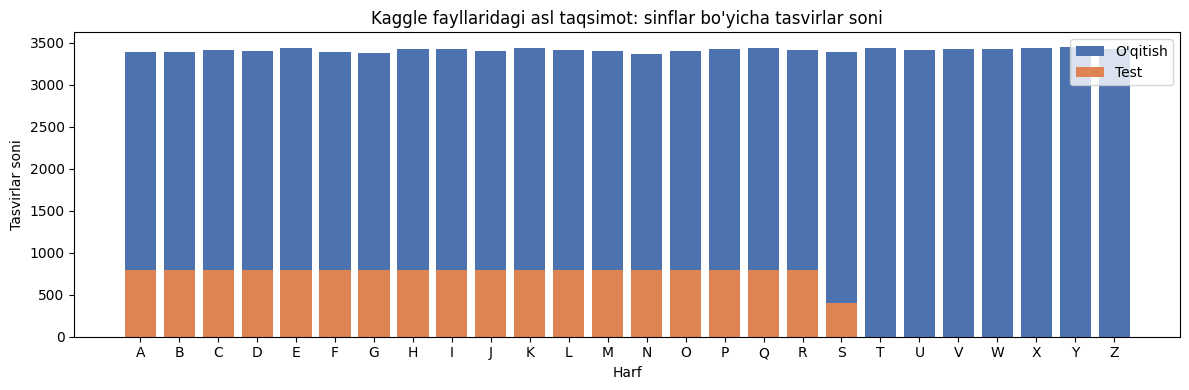

In [6]:
counts = pd.DataFrame({
    "Harf": CLASS_NAMES,
    "O'qitish": np.bincount(y_train_full, minlength=NUM_CLASSES),
    "Test": np.bincount(y_test_orig, minlength=NUM_CLASSES),
})
display(counts.set_index("Harf").T)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(counts["Harf"], counts["O'qitish"], color="#4C72B0", label="O'qitish")
ax.bar(counts["Harf"], counts["Test"], color="#DD8452", label="Test")
ax.set_title("Kaggle fayllaridagi asl taqsimot: sinflar bo'yicha tasvirlar soni")
ax.set_xlabel("Harf"); ax.set_ylabel("Tasvirlar soni"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_sinf_taqsimoti.png", dpi=150); plt.show()

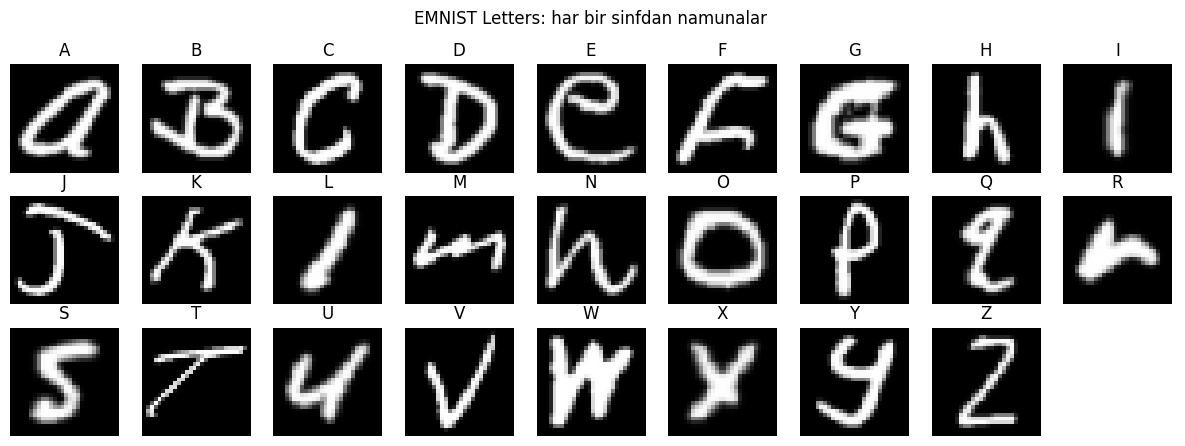

In [7]:
# Har bir harfdan bittadan namuna
fig, axes = plt.subplots(3, 9, figsize=(12, 4.5))
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < NUM_CLASSES:
        idx = np.where(y_train_full == i)[0][0]
        ax.imshow(X_train_full[idx], cmap="gray")
        ax.set_title(CLASS_NAMES[i])
plt.suptitle("EMNIST Letters: har bir sinfdan namunalar")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_namunalar.png", dpi=150); plt.show()

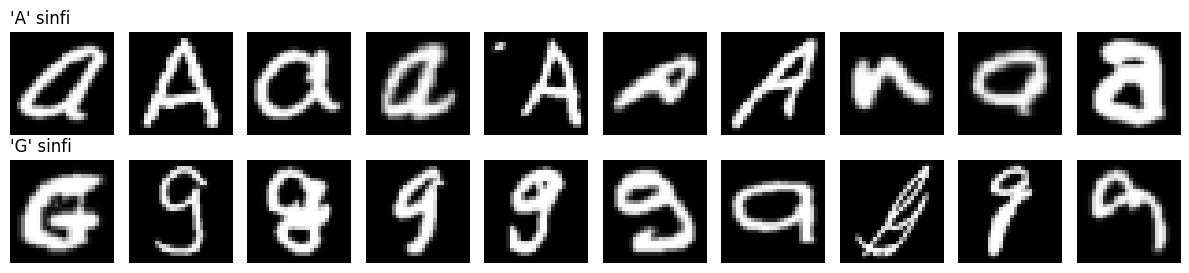

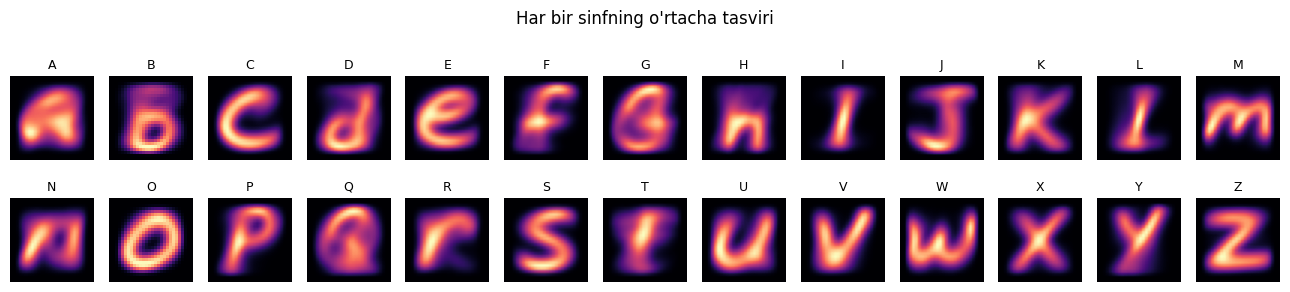

In [8]:
# Bitta harf turli yozuvlarda (katta/kichik harflar bitta sinfda)
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for r, letter in enumerate(["A", "G"]):
    idxs = np.where(y_train_full == CLASS_NAMES.index(letter))[0][:10]
    for c, idx in enumerate(idxs):
        axes[r, c].imshow(X_train_full[idx], cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(f"'{letter}' sinfi", loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_sinf_ichidagi_xilma_xillik.png", dpi=150); plt.show()

# O'rtacha tasvirlar
fig, axes = plt.subplots(2, 13, figsize=(13, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[y_train_full == i].mean(axis=0), cmap="magma"); ax.axis("off")
    ax.set_title(CLASS_NAMES[i], fontsize=9)
plt.suptitle("Har bir sinfning o'rtacha tasviri")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_ortacha_tasvirlar.png", dpi=150); plt.show()

**Kuzatuvlar:**
* **Muhim muammo:** Kaggle'dagi `emnist-letters-test.csv` fayli sinf bo'yicha tartiblangan va qirqilgan: unda A–R harflaridan 800 tadan, S dan 400 ta bor, **T–Z harflari esa umuman yo'q**. Bunday test to'plami bilan 7 ta harf baholanmaydi va natijalar noto'g'ri bo'ladi.
* O'qitish fayli deyarli muvozanatlangan: har bir harf uchun 3 365–3 453 ta tasvir.
* Bo'sh qiymatlar yo'q, piksellar 0–255 oralig'ida; bir nechta takrorlangan qator bor.
* Bitta sinf ichida katta va kichik harflar aralash (masalan, `A` va `a`, `G` va `g`), bu vazifani murakkablashtiradi.
* Ba'zi harflar shakli jihatidan juda o'xshash (`I`–`L`, `G`–`Q`, `U`–`V`), shuning uchun ular orasida xatolar kutiladi.

## 4. Dastlabki ishlov berish va to'plamlarga ajratish

1. Test faylidagi muammo tufayli ikkala fayl birlashtiriladi va takrorlangan qatorlar olib tashlanadi.
2. Ma'lumotlar stratifikatsiyalangan holda **80% o'qitish / 10% validatsiya / 10% test** to'plamlariga ajratiladi — har bir to'plamda barcha 26 harf teng ulushda bo'ladi. Test to'plami faqat yakuniy baholashda ishlatiladi.
3. Piksel qiymatlarini `[0, 1]` oralig'iga normallashtirish (`/255`).
4. Kanal o'lchamini qo'shish: `(N, 28, 28) → (N, 28, 28, 1)`.
4. O'qitish paytida ma'lumotlarni ko'paytirish (augmentatsiya): kichik burish, siljitish va masshtablash. Gorizontal aks ettirish **ishlatilmaydi**, chunki u harf shaklini buzadi.

Birlashtirilgan: 103600 ta, takrorlanganlar olib tashlangach: 103598 ta


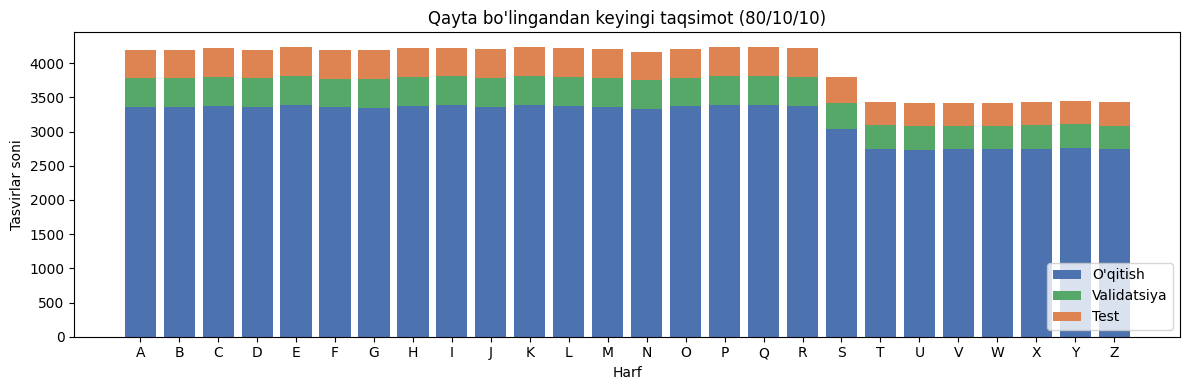

,To'plam,Tasvirlar soni,"Ulushi, %"
0,O'qitish,82878,80.0
1,Validatsiya,10360,10.0
2,Test,10360,10.0


In [9]:
all_df = pd.concat([train_df, test_df], ignore_index=True)
n_before = len(all_df)
all_df = all_df.drop_duplicates().reset_index(drop=True)
print(f"Birlashtirilgan: {n_before} ta, takrorlanganlar olib tashlangach: {len(all_df)} ta")
X_all, y_all = to_arrays(all_df)

# 80% / 10% / 10% (stratifikatsiyalangan)
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X_all, y_all, test_size=0.10, stratify=y_all, random_state=SEED)
X_train_u8, X_val_u8, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=1/9, stratify=y_tmp, random_state=SEED)

norm = lambda X: (X.astype("float32") / 255.0)[..., None]
X_train, X_val, X_test_f = norm(X_train_u8), norm(X_val_u8), norm(X_test)

fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(NUM_CLASSES)
for name, yy, col in [("O'qitish", y_train, "#4C72B0"), ("Validatsiya", y_val, "#55A868"), ("Test", y_test, "#DD8452")]:
    c = np.bincount(yy, minlength=NUM_CLASSES)
    ax.bar(CLASS_NAMES, c, bottom=bottom, color=col, label=name); bottom += c
ax.set_title("Qayta bo'lingandan keyingi taqsimot (80/10/10)")
ax.set_xlabel("Harf"); ax.set_ylabel("Tasvirlar soni"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01b_yangi_taqsimot.png", dpi=150); plt.show()

split_df = pd.DataFrame({
    "To'plam": ["O'qitish", "Validatsiya", "Test"],
    "Tasvirlar soni": [len(X_train), len(X_val), len(X_test_f)],
})
split_df["Ulushi, %"] = (100 * split_df["Tasvirlar soni"] / split_df["Tasvirlar soni"].sum()).round(1)
split_df

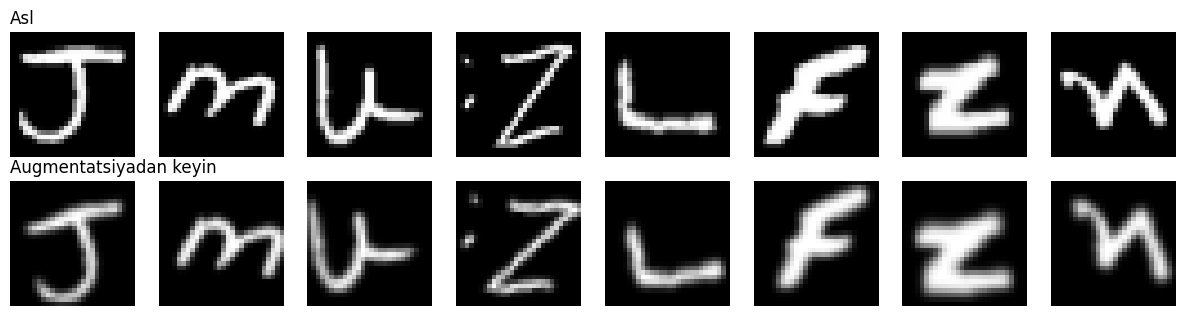

In [10]:
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test_f, y_test)

augment = keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant"),          # ±18°
    layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
    layers.RandomZoom(0.08, fill_mode="constant"),
], name="augmentatsiya")

# Augmentatsiya natijasini ko'rish
sample = X_train[:8]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(sample[i, ..., 0], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(augment(sample[i:i+1], training=True)[0, ..., 0], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Asl", loc="left"); axes[1, 0].set_title("Augmentatsiyadan keyin", loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_augmentatsiya.png", dpi=150); plt.show()

## 5. CNN arxitekturasi

Model uchta konvolyutsion blokdan va to'liq bog'langan klassifikatordan iborat:

```
Kirish 28×28×1
 └─ Augmentatsiya (faqat o'qitishda)
 └─ Blok 1: Conv(32,3×3) → BN → ReLU → Conv(32,3×3) → BN → ReLU → MaxPool(2×2) → Dropout
 └─ Blok 2: Conv(64,3×3) → BN → ReLU → Conv(64,3×3) → BN → ReLU → MaxPool(2×2) → Dropout
 └─ Blok 3: Conv(128,3×3) → BN → ReLU → GlobalAveragePooling
 └─ Dense(256) → BN → ReLU → Dropout
 └─ Dense(26, softmax)
```

* **Konvolyutsiya qatlamlari** chiziqlar, burchaklar, egri chiziqlar kabi lokal belgilarni ajratadi; chuqurroq qatlamlar ularni harf qismlariga birlashtiradi.
* **BatchNormalization** o'qitishni barqarorlashtiradi va tezlashtiradi.
* **MaxPooling** fazoviy o'lchamni kamaytiradi va kichik siljishlarga chidamlilik beradi.
* **Dropout** va **augmentatsiya** ortiqcha moslashuvning (overfitting) oldini oladi.
* **Yo'qotish funksiyasi:** `sparse_categorical_crossentropy`; **optimizator:** Adam.

In [11]:
def build_model(dropout=0.3, dense_units=256, lr=1e-3, use_augment=True):
    inputs = keras.Input(shape=(28, 28, 1))
    x = augment(inputs) if use_augment else inputs

    def conv_bn(x, filters):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        return layers.ReLU()(x)

    x = conv_bn(x, 32); x = conv_bn(x, 32)
    x = layers.MaxPooling2D()(x); x = layers.Dropout(dropout * 0.5)(x)

    x = conv_bn(x, 64); x = conv_bn(x, 64)
    x = layers.MaxPooling2D()(x); x = layers.Dropout(dropout * 0.5)(x)

    x = conv_bn(x, 128)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(dense_units, use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="EMNIST_Letters_CNN")
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_model().summary()

Model: "EMNIST_Letters_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentatsiya (Sequential)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 180,282 (704.23 KB)

 Trainable params: 179,130 (699.73 KB)

 Non-trainable params: 1,152 (4.50 KB)

## 6. Giperparametrlarni sozlash

Vaqtni tejash uchun har bir konfiguratsiya o'qitish to'plamining 25% qismida 4 epoxa davomida o'qitiladi va validatsiya to'plamidagi aniqlik bo'yicha taqqoslanadi. Tekshiriladigan giperparametrlar: o'qitish tezligi (learning rate), Dropout darajasi va Dense qatlamdagi neyronlar soni.

In [12]:
search_space = [
    {"lr": 1e-3, "dropout": 0.3, "dense_units": 256},
    {"lr": 3e-3, "dropout": 0.3, "dense_units": 256},
    {"lr": 3e-4, "dropout": 0.3, "dense_units": 256},
    {"lr": 1e-3, "dropout": 0.5, "dense_units": 256},
    {"lr": 1e-3, "dropout": 0.3, "dense_units": 128},
]

sub_idx = np.random.RandomState(SEED).choice(len(X_train), len(X_train) // 4, replace=False)
sub_ds = make_ds(X_train[sub_idx], y_train[sub_idx], shuffle=True)

results = []
for cfg in search_space:
    tf.random.set_seed(SEED)
    m = build_model(**cfg)
    t0 = time.time()
    h = m.fit(sub_ds, validation_data=val_ds, epochs=4, verbose=0)
    results.append({**cfg,
                    "val_accuracy": max(h.history["val_accuracy"]),
                    "val_loss": min(h.history["val_loss"]),
                    "vaqt, s": round(time.time() - t0, 1)})
    print(cfg, "->", round(results[-1]["val_accuracy"], 4))

tuning_df = pd.DataFrame(results).sort_values("val_accuracy", ascending=False).reset_index(drop=True)
tuning_df.to_csv(f"{OUT_DIR}/giperparametrlar.csv", index=False)
tuning_df

{'lr': 0.001, 'dropout': 0.3, 'dense_units': 256} -> 0.8946
{'lr': 0.003, 'dropout': 0.3, 'dense_units': 256} -> 0.8909
{'lr': 0.0003, 'dropout': 0.3, 'dense_units': 256} -> 0.8628
{'lr': 0.001, 'dropout': 0.5, 'dense_units': 256} -> 0.8899
{'lr': 0.001, 'dropout': 0.3, 'dense_units': 128} -> 0.8723


,lr,dropout,dense_units,val_accuracy,val_loss,"vaqt, s"
0,0.0010,0.3,256,0.894595,0.316694,27.8
1,0.0030,0.3,256,0.890927,0.334661,19.9
2,0.0010,0.5,256,0.889865,0.324995,20.9
3,0.0010,0.3,128,0.872297,0.384006,19.8
4,0.0003,0.3,256,0.862838,0.440965,19.7


In [13]:
best_cfg = tuning_df.iloc[0][["lr", "dropout", "dense_units"]].to_dict()
best_cfg["dense_units"] = int(best_cfg["dense_units"])
print("Eng yaxshi konfiguratsiya:", best_cfg)

Eng yaxshi konfiguratsiya: {'lr': 0.001, 'dropout': 0.3, 'dense_units': 256}


## 7. Yakuniy modelni o'qitish

Eng yaxshi giperparametrlar bilan model to'liq o'qitish to'plamida o'qitiladi. Callback'lar:
* `EarlyStopping` — validatsiya yo'qotishi 5 epoxa davomida yaxshilanmasa to'xtatadi va eng yaxshi og'irliklarni tiklaydi;
* `ReduceLROnPlateau` — validatsiya yo'qotishi 2 epoxa yaxshilanmasa o'qitish tezligini 2 marta kamaytiradi;
* `ModelCheckpoint` — eng yaxshi modelni faylga saqlaydi.

In [14]:
EPOCHS = 30
tf.random.set_seed(SEED)
model = build_model(**best_cfg)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(f"{OUT_DIR}/emnist_letters_cnn.keras", monitor="val_accuracy", save_best_only=True),
]

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
train_time = time.time() - t0
print(f"O'qitish vaqti: {train_time/60:.1f} daqiqa, epoxalar soni: {len(history.history['loss'])}")

Epoch 1/30
648/648 - 22s - 34ms/step - accuracy: 0.7809 - loss: 0.7220 - val_accuracy: 0.8718 - val_loss: 0.4057 - learning_rate: 0.0010
Epoch 2/30
648/648 - 15s - 23ms/step - accuracy: 0.8976 - loss: 0.3113 - val_accuracy: 0.9017 - val_loss: 0.2937 - learning_rate: 0.0010
Epoch 3/30
648/648 - 15s - 23ms/step - accuracy: 0.9112 - loss: 0.2644 - val_accuracy: 0.8846 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 4/30
648/648 - 15s - 23ms/step - accuracy: 0.9162 - loss: 0.2465 - val_accuracy: 0.8891 - val_loss: 0.3269 - learning_rate: 0.0010
Epoch 5/30
648/648 - 15s - 22ms/step - accuracy: 0.9276 - loss: 0.2119 - val_accuracy: 0.9334 - val_loss: 0.1833 - learning_rate: 5.0000e-04
Epoch 6/30
648/648 - 14s - 22ms/step - accuracy: 0.9311 - loss: 0.1993 - val_accuracy: 0.9216 - val_loss: 0.2343 - learning_rate: 5.0000e-04
Epoch 7/30
648/648 - 14s - 22ms/step - accuracy: 0.9301 - loss: 0.1986 - val_accuracy: 0.9205 - val_loss: 0.2387 - learning_rate: 5.0000e-04
Epoch 8/30
648/648 - 15s - 23

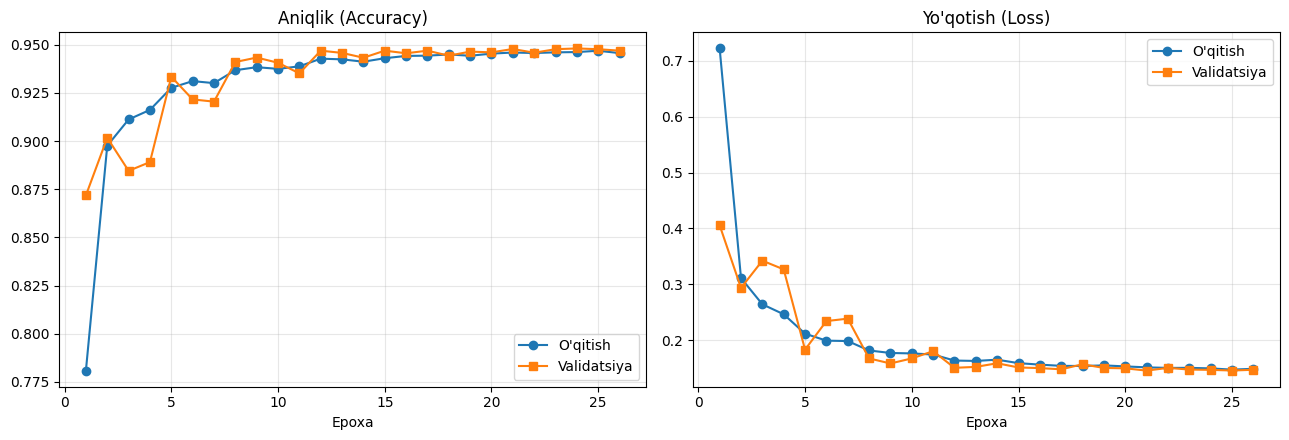

Eng yaxshi epoxa: 21, val_accuracy = 0.9478, val_loss = 0.1458


In [15]:
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
hist.to_csv(f"{OUT_DIR}/oqitish_tarixi.csv", index_label="epoch")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.index, hist["accuracy"], "o-", label="O'qitish")
axes[0].plot(hist.index, hist["val_accuracy"], "s-", label="Validatsiya")
axes[0].set_title("Aniqlik (Accuracy)"); axes[0].set_xlabel("Epoxa"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(hist.index, hist["loss"], "o-", label="O'qitish")
axes[1].plot(hist.index, hist["val_loss"], "s-", label="Validatsiya")
axes[1].set_title("Yo'qotish (Loss)"); axes[1].set_xlabel("Epoxa"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_oqitish_grafiklari.png", dpi=150); plt.show()

best_ep = int(hist["val_loss"].idxmin())
print(f"Eng yaxshi epoxa: {best_ep}, val_accuracy = {hist.loc[best_ep, 'val_accuracy']:.4f}, val_loss = {hist.loc[best_ep, 'val_loss']:.4f}")

## 8. Test to'plamida baholash

In [16]:
test_loss, test_acc_keras = model.evaluate(test_ds, verbose=0)
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
    "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
    "Test loss": test_loss,
}
metrics_df = pd.DataFrame(metrics, index=["Test"]).T.round(4)
metrics_df.to_csv(f"{OUT_DIR}/test_metrikalari.csv")
metrics_df

,Test
Accuracy,0.9498
Precision (macro),0.9518
Recall (macro),0.9511
F1-score (macro),0.9509
Test loss,0.1424


In [17]:
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True, digits=4)
report_df = pd.DataFrame(report).T.round(4)
report_df.to_csv(f"{OUT_DIR}/sinflar_boyicha_hisobot.csv")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

           A     0.9643    0.9643    0.9643       420
           B     0.9834    0.9881    0.9857       420
           C     0.9926    0.9502    0.9709       422
           D     0.9576    0.9690    0.9633       420
           E     0.9612    0.9929    0.9768       424
           F     0.9788    0.9905    0.9846       419
           G     0.8872    0.8469    0.8666       418
           H     0.9765    0.9858    0.9811       422
           I     0.8203    0.6690    0.7370       423
           J     0.9854    0.9619    0.9735       420
           K     0.9905    0.9882    0.9894       424
           L     0.7265    0.8456    0.7816       421
           M     0.9767    1.0000    0.9882       420
           N     0.9779    0.9591    0.9684       416
           O     0.9830    0.9620    0.9724       421
           P     0.9905    0.9858    0.9882       423
           Q     0.8506    0.9269    0.8871       424
           R     0.9639    

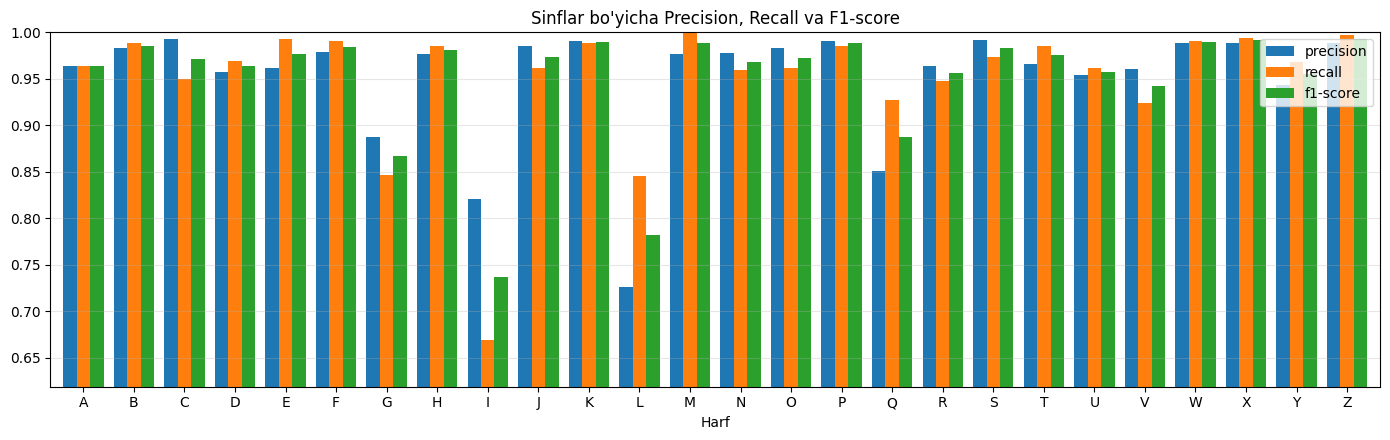

In [18]:
per_class = report_df.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]]
ax = per_class.plot(kind="bar", figsize=(14, 4.5), width=0.8)
ax.set_ylim(max(0.0, per_class.values.min() - 0.05), 1.0); ax.set_title("Sinflar bo'yicha Precision, Recall va F1-score")
ax.set_xlabel("Harf"); ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/07_sinflar_boyicha_metrikalar.png", dpi=150); plt.show()

## 9. Chalkashlik matritsasi (Confusion matrix) va xatolar tahlili

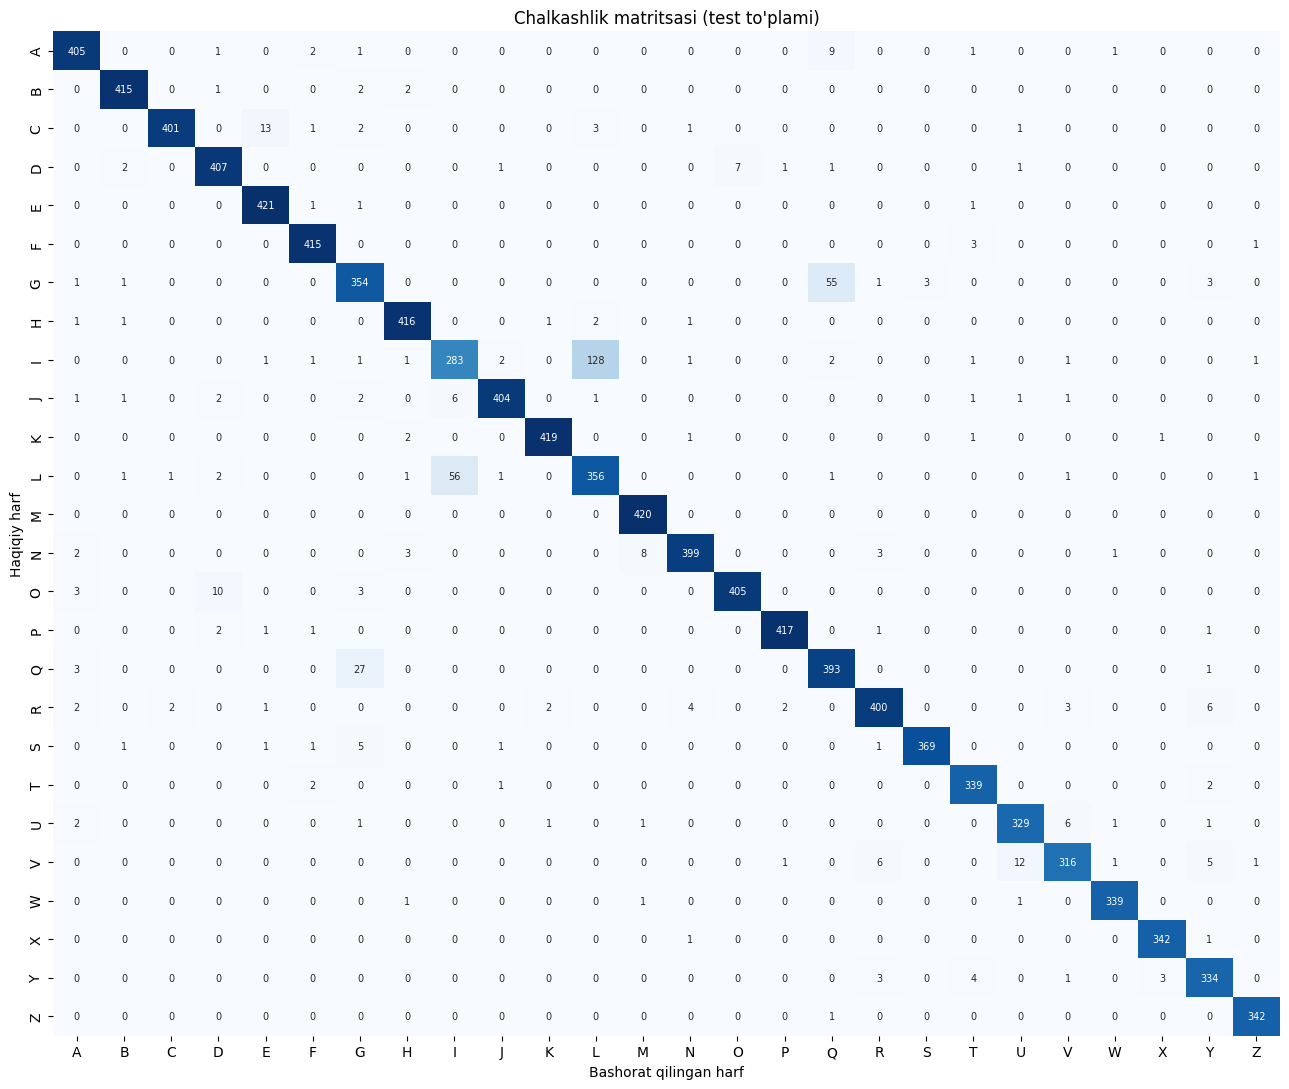

In [19]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(13, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 7})
plt.title("Chalkashlik matritsasi (test to'plami)")
plt.xlabel("Bashorat qilingan harf"); plt.ylabel("Haqiqiy harf")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/08_chalkashlik_matritsasi.png", dpi=150); plt.show()

In [20]:
# Eng ko'p adashtirilgan juftliklar
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], cm_off[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0]
confused_df = pd.DataFrame(pairs, columns=["Haqiqiy", "Bashorat", "Soni"]).sort_values("Soni", ascending=False).head(10).reset_index(drop=True)
confused_df.to_csv(f"{OUT_DIR}/eng_kop_adashtirilgan.csv", index=False)
confused_df

,Haqiqiy,Bashorat,Soni
0,I,L,128
1,L,I,56
2,G,Q,55
3,Q,G,27
4,C,E,13
5,V,U,12
6,O,D,10
7,A,Q,9
8,N,M,8
9,D,O,7


Noto'g'ri tasniflanganlar: 520 / 10360 (5.02%)


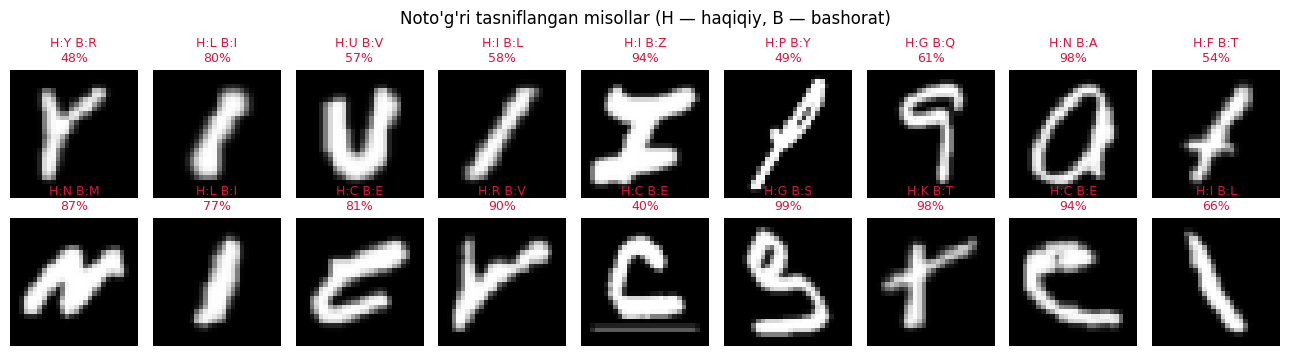

In [21]:
# Noto'g'ri tasniflangan namunalar
wrong = np.where(y_pred != y_test)[0]
print(f"Noto'g'ri tasniflanganlar: {len(wrong)} / {len(y_test)} ({100*len(wrong)/len(y_test):.2f}%)")
pick = np.random.RandomState(SEED).choice(wrong, 18, replace=False)
fig, axes = plt.subplots(2, 9, figsize=(13, 3.6))
for ax, idx in zip(axes.flat, pick):
    ax.imshow(X_test[idx], cmap="gray"); ax.axis("off")
    ax.set_title(f"H:{CLASS_NAMES[y_test[idx]]} B:{CLASS_NAMES[y_pred[idx]]}\n{y_prob[idx].max():.0%}", fontsize=9, color="crimson")
plt.suptitle("Noto'g'ri tasniflangan misollar (H — haqiqiy, B — bashorat)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/09_xato_misollar.png", dpi=150); plt.show()

## 10. Saqlangan modelni yuklab, yangi tasvirlarda sinash

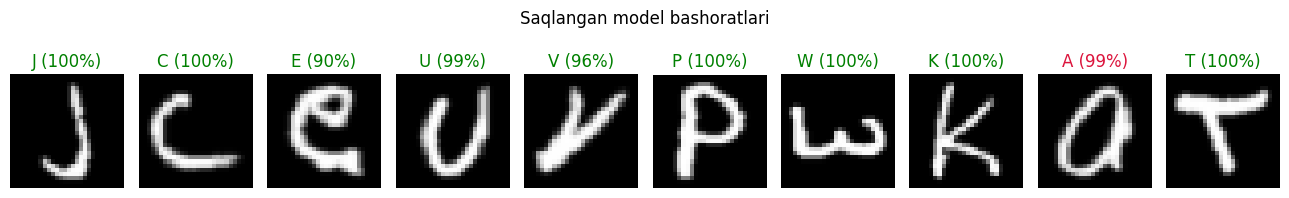

Misol, top-3: [('J', 0.9990280866622925), ('D', 0.0005669776001013815), ('I', 0.00010660246334737167)]


In [22]:
loaded = keras.models.load_model(f"{OUT_DIR}/emnist_letters_cnn.keras")

def predict_letter(img28):
    # img28: 28x28 kulrang tasvir (0-255, oq harf qora fonda)
    x = (np.asarray(img28, dtype="float32") / 255.0).reshape(1, 28, 28, 1)
    p = loaded.predict(x, verbose=0)[0]
    top3 = p.argsort()[::-1][:3]
    return [(CLASS_NAMES[k], float(p[k])) for k in top3]

idxs = np.random.RandomState(7).choice(len(X_test), 10, replace=False)
fig, axes = plt.subplots(1, 10, figsize=(13, 2.2))
for ax, idx in zip(axes, idxs):
    top = predict_letter(X_test[idx])
    ok = top[0][0] == CLASS_NAMES[y_test[idx]]
    ax.imshow(X_test[idx], cmap="gray"); ax.axis("off")
    ax.set_title(f"{top[0][0]} ({top[0][1]:.0%})", color="green" if ok else "crimson")
plt.suptitle("Saqlangan model bashoratlari")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/10_bashoratlar.png", dpi=150); plt.show()
print("Misol, top-3:", predict_letter(X_test[idxs[0]]))

In [23]:
# Yakuniy natijalar jamlanmasi
summary = {
    "Parametrlar soni": model.count_params(),
    "Eng yaxshi giperparametrlar": best_cfg,
    "O'qitilgan epoxalar": len(hist),
    "O'qitish vaqti, daqiqa": round(train_time / 60, 1),
    **{k: round(float(v), 4) for k, v in metrics.items()},
}
import json
json.dump({
    "params": int(model.count_params()), "train_minutes": round(train_time / 60, 1),
    "device": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
    "duplicates": int(train_df.duplicated().sum()), "epochs": len(hist), **best_cfg,
}, open(f"{OUT_DIR}/info.json", "w"), indent=2)
pd.Series(summary, name="Qiymat").to_frame()

,Qiymat
Parametrlar soni,180282
Eng yaxshi giperparametrlar,"{'lr': 0.001, 'dropout': 0.3, 'dense_units': 256}"
O'qitilgan epoxalar,26
"O'qitish vaqti, daqiqa",6.6
Accuracy,0.9498
Precision (macro),0.9518
Recall (macro),0.9511
F1-score (macro),0.9509
Test loss,0.1424


In [24]:
# Natijalar papkasini arxivlab yuklab olish (Colab'da avtomatik yuklanadi)
import shutil
shutil.make_archive("natijalar", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("natijalar.zip")
except ImportError:
    print("natijalar.zip yaratildi:", os.path.abspath("natijalar.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Xulosa

* EMNIST Letters to'plami (26 sinf, 103 600 tasvir) Kaggle'dan yuklab olindi va tahlil qilindi. Kaggle test faylida T–Z harflari yo'qligi aniqlandi, shuning uchun fayllar birlashtirilib, 80/10/10 nisbatda stratifikatsiyalangan holda qayta bo'lindi.
* BatchNormalization, Dropout va augmentatsiyaga ega uch blokli CNN modeli ishlab chiqildi.
* Giperparametrlar (learning rate, dropout, dense neyronlar soni) qisqa tajribalar orqali tanlandi.
* Test to'plamidagi Accuracy, Precision, Recall va F1-score qiymatlari yuqoridagi jadvalda keltirilgan. Model qo'yilgan ≥ 90% maqsadga erishdi.
* Xatolarning asosiy qismi shakli o'xshash harflar (`I`–`L`, `G`–`Q`, `U`–`V` kabi) orasida yuz bermoqda; bunga sinf ichida katta va kichik harflarning aralashganligi ham sabab bo'ladi.

**Takomillashtirish yo'nalishlari:** chuqurroq arxitektura (ResNet), bir nechta modellar ansambli, kuchliroq augmentatsiya (elastik deformatsiya), katta va kichik harflarni alohida sinflarga ajratish (EMNIST ByClass).